In [28]:
%pip install plotly


U.S. CENSUS PROPORTIONAL SYMBOL MAP — 1920 VS. 2020
This example compares state population counts across a century.
It retrieves official Census data and 2020 TIGER/Line boundaries.
No Census API key is required for the historical table source.

STEP 1 — RETRIEVING HISTORICAL CENSUS POPULATION DATA
Source: U.S. Census Bureau Historical Population Change Data
Retrieving the official 1920 and 2020 state population counts...


/tmp/ipykernel_786/686232993.py:143: FutureWarning:

Passing literal html to 'read_html' is deprecated and will be removed in a future version. To read from a literal string, wrap it in a 'StringIO' object.



Retrieved 57 historical geography records.
         NAME  POP_1920  POP_2020
United States 106021568 331449281
    Northeast  29662053  57609148
      Midwest  34019792  68985454
        South  33125803 126266107
         West   9213920  78588572
      Alabama   2348174   5024279
       Alaska     55036    733391
      Arizona    334162   7151502

STEP 2 — LOADING 2020 TIGER/LINE STATE BOUNDARIES
Saved: /content/population_comparison_1920_2020_output/tl_2020_us_state.zip
Loaded 56 boundary records.
Boundary coordinate system: EPSG:4269

STEP 3 — JOINING AND VALIDATING THE DATA
Successfully matched 51 geographies.
2020 total across mapped geographies: 331,449,281
1920 total across mapped geographies: 106,021,568

STEP 4 — CREATING THE PROPORTIONAL SYMBOL MAP

STEP 4B — CREATING INTERACTIVE HOVER MAP

STEP 5 — EXPORTING OUTPUT FILES
Export completed:
  /content/population_comparison_1920_2020_output/population_comparison_1920_2020.png
  /content/population_comparison_1920_2020_output/pop

Displaying the high-resolution static reference-style map.


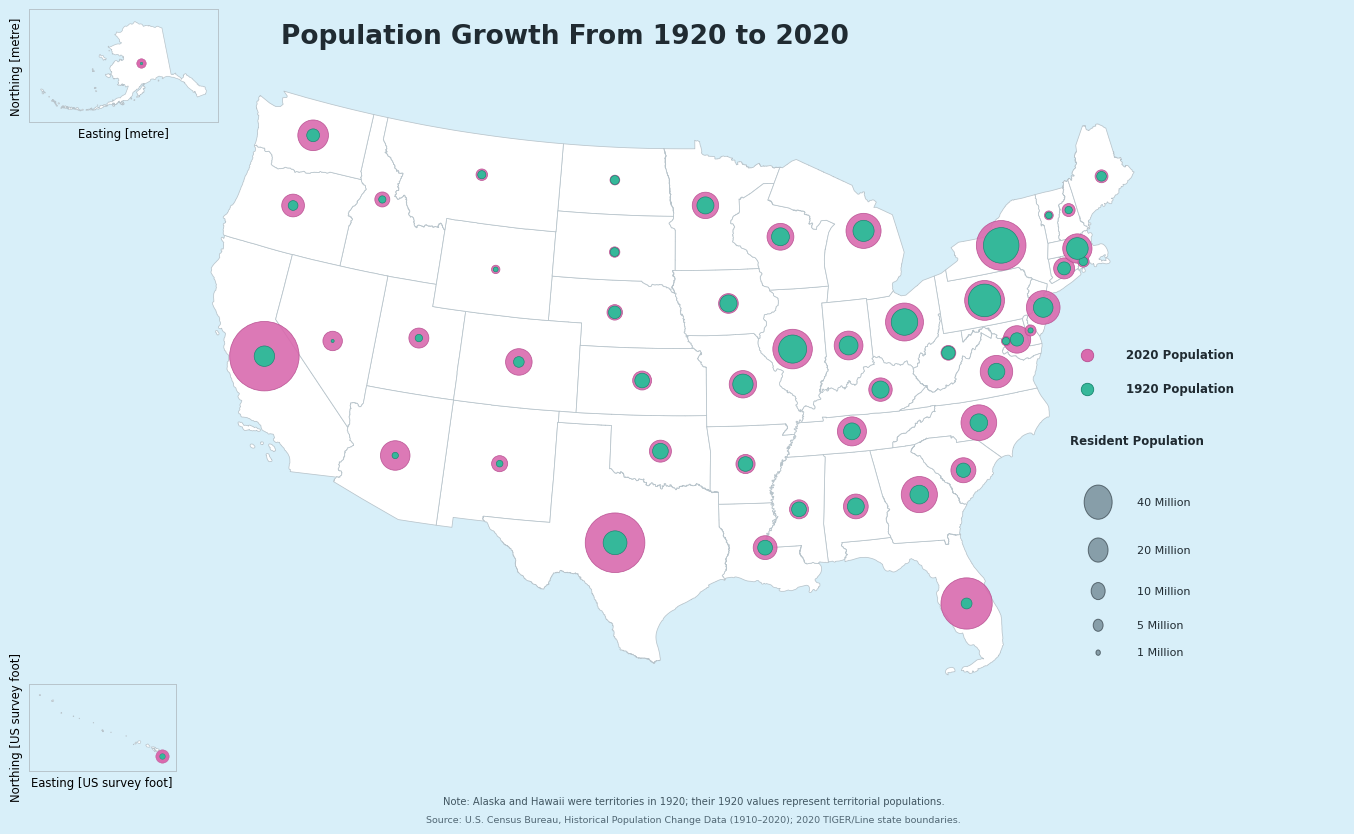

In [32]:
"""
U.S. Census Proportional Symbol Map: 1920 vs. 2020
=================================================

Purpose
-------
Compare state-level population counts from the 1920 and 2020 Censuses.
Each state receives two proportional symbols:
    - Green: 1920 population
    - Pink:  2020 population

Data sources
------------
1. U.S. Census Bureau, Historical Population Change Data (1910-2020):
   https://www.census.gov/data/tables/time-series/dec/popchange-data-text.html
   This official Census page provides state resident population counts for
   both 1920 and 2020. It is used because the Census API does not provide
   1920 data as an API dataset.
2. U.S. Census Bureau, 2020 TIGER/Line state boundaries:
   https://www2.census.gov/geo/tiger/TIGER2020/STATE/tl_2020_us_state.zip

Important interpretation note
------------------------------
Alaska and Hawaii were territories in 1920, not states. Their 1920 values
represent the populations of the territories that later became states.
The 2020 values are state populations. The map includes them for geographic
continuity, and this difference must be disclosed when interpreting results.

The 1920 and 2020 population counts are official decennial census counts,
not ACS estimates. This script does not require a Census API key because
the historical data are retrieved from an official Census Bureau table.

Packages
--------
requests, pandas, geopandas, matplotlib, numpy, plotly
"""

from pathlib import Path
import sys
import traceback
import warnings

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import plotly.graph_objects as go
from matplotlib.lines import Line2D
from matplotlib.patches import Circle
from matplotlib.ticker import FuncFormatter

# ---------------------------------------------------------------------------
# USER SETTINGS
# ---------------------------------------------------------------------------

DATA_PAGE_URL = (
    "https://www.census.gov/data/tables/time-series/dec/"
    "popchange-data-text.html"
)

TIGER_URL = (
    "https://www2.census.gov/geo/tiger/TIGER2020/STATE/"
    "tl_2020_us_state.zip"
)

YEAR_OLDER = 1920
YEAR_NEWER = 2020

# Marker areas are measured in points squared. This value controls the
# maximum visual area assigned to the largest population.
MAX_MARKER_AREA = 2500

# The paired symbols are shifted slightly left/right of each state centroid
# so both years remain visible. Increase this for dense Northeast states.
PAIR_OFFSET_FRACTION = 0.006

# ---------------------------------------------------------------------------
# FILE LOCATIONS
# ---------------------------------------------------------------------------

# __file__ exists when this code runs as a .py file. Jupyter notebooks do
# not define __file__, so Path.cwd() is used as a safe fallback.
try:
    SCRIPT_FOLDER = Path(__file__).resolve().parent
except NameError:
    SCRIPT_FOLDER = Path.cwd()

OUTPUT_FOLDER = SCRIPT_FOLDER / "population_comparison_1920_2020_output"
OUTPUT_FOLDER.mkdir(parents=True, exist_ok=True)


# ---------------------------------------------------------------------------
# GENERAL HELPERS
# ---------------------------------------------------------------------------

def print_section(title):
    """Print a clear section heading in the console or notebook output."""
    print("\n" + "=" * 78)
    print(title)
    print("=" * 78)


def download_file(url, destination, description):
    """Download a file with a timeout and a helpful error message."""
    print(f"Downloading {description}...")
    response = requests.get(url, timeout=120)
    response.raise_for_status()
    destination.write_bytes(response.content)
    print(f"Saved: {destination}")
    return destination


def normalize_text(value):
    """Normalize labels to make table matching more reliable."""
    return " ".join(str(value).replace("\xa0", " ").strip().split())


# ---------------------------------------------------------------------------
# STEP 1 — RETRIEVE OFFICIAL HISTORICAL CENSUS POPULATION COUNTS
# ---------------------------------------------------------------------------

def get_historical_population():
    """
    Read the official Census Bureau historical population table.

    The table contains a state/region label followed by Resident Population
    and Percent Change rows. We retain only the Resident Population values
    for 1920 and 2020.
    """
    print_section("STEP 1 — RETRIEVING HISTORICAL CENSUS POPULATION DATA")
    print("Source: U.S. Census Bureau Historical Population Change Data")
    print("Retrieving the official 1920 and 2020 state population counts...")

    response = requests.get(
        DATA_PAGE_URL,
        timeout=120,
        headers={"User-Agent": "Mozilla/5.0 (compatible; CensusVisualizationExample/1.0)"}
    )
    response.raise_for_status()

    # pandas reads the HTML table directly from the downloaded page content.
    tables = pd.read_html(response.text, flavor="lxml")

    target_table = None
    for table in tables:
        table_as_text = table.astype(str).to_string()
        if "Alabama" in table_as_text and "Resident Population" in table_as_text:
            target_table = table.copy()
            break

    if target_table is None:
        raise ValueError(
            "Could not find the expected state population table on the "
            "Census Bureau webpage. The page layout may have changed."
        )

    # Flatten any multi-level column headers produced by read_html.
    if isinstance(target_table.columns, pd.MultiIndex):
        target_table.columns = [
            " ".join(normalize_text(part) for part in col if normalize_text(part))
            for col in target_table.columns
        ]
    else:
        target_table.columns = [normalize_text(col) for col in target_table.columns]

    # The page uses a two-row pattern for each geography:
    # geography name, then Resident Population / Percent Change.
    # We extract the row labelled Resident Population and identify the year
    # columns by looking for the 1920 and 2020 labels in the headers.
    columns = list(target_table.columns)

    def find_year_column(year):
        candidates = [
            col for col in columns
            if str(year) in col and "Census" in col
        ]
        if candidates:
            return candidates[0]

        # Some pandas versions flatten the headers differently.
        candidates = [col for col in columns if str(year) in col]
        if candidates:
            return candidates[0]

        raise KeyError(
            f"Could not identify the {year} column. Available columns: {columns}"
        )

    year_1920_col = find_year_column(YEAR_OLDER)
    year_2020_col = find_year_column(YEAR_NEWER)

    # Determine which column contains row labels such as state names and
    # "Resident Population".
    label_col = columns[0]

    rows = []
    current_geography = None

    for _, row in target_table.iterrows():
        label = normalize_text(row[label_col])

        if label in ("", "nan", "None"):
            continue

        if label == "Resident Population":
            if current_geography is not None:
                value_1920 = pd.to_numeric(row[year_1920_col], errors="coerce")
                value_2020 = pd.to_numeric(row[year_2020_col], errors="coerce")

                if pd.notna(value_1920) and pd.notna(value_2020):
                    rows.append({
                        "NAME": current_geography,
                        "POP_1920": int(value_1920),
                        "POP_2020": int(value_2020),
                    })
            continue

        if label == "Percent Change":
            continue

        # Exclude section headings and national/region totals. Valid state
        # names are checked later against the TIGER/Line boundary records.
        current_geography = label

    population = pd.DataFrame(rows)

    if population.empty:
        raise ValueError(
            "The Census population table was downloaded, but no population "
            "records could be extracted. Check the webpage table structure."
        )

    # Remove national totals, Census regions, Puerto Rico, and other entries.
    population["NAME"] = population["NAME"].str.replace(
        r"\s+", " ", regex=True
    ).str.strip()

    population = population.drop_duplicates(subset="NAME")

    print(f"Retrieved {len(population)} historical geography records.")
    print(population.head(8).to_string(index=False))

    return population


# ---------------------------------------------------------------------------
# STEP 2 — DOWNLOAD 2020 TIGER/LINE STATE BOUNDARIES
# ---------------------------------------------------------------------------

def get_state_boundaries():
    """Download and load official 2020 TIGER/Line state boundaries."""
    print_section("STEP 2 — LOADING 2020 TIGER/LINE STATE BOUNDARIES")

    zip_path = OUTPUT_FOLDER / "tl_2020_us_state.zip"
    download_file(TIGER_URL, zip_path, "2020 TIGER/Line state boundaries")

    # GeoPandas can read a zipped shapefile directly.
    boundaries = gpd.read_file(f"zip://{zip_path}")

    required = {"NAME", "GEOID", "geometry"}
    missing = required.difference(boundaries.columns)
    if missing:
        raise ValueError(f"TIGER/Line file is missing columns: {sorted(missing)}")

    print(f"Loaded {len(boundaries)} boundary records.")
    print(f"Boundary coordinate system: {boundaries.crs}")

    return boundaries


# ---------------------------------------------------------------------------
# STEP 3 — JOIN AND VALIDATE POPULATION DATA
# ---------------------------------------------------------------------------

def prepare_map_data(population, boundaries):
    """Join the historical counts to state boundaries and calculate change."""
    print_section("STEP 3 — JOINING AND VALIDATING THE DATA")

    # Exclude territories and island areas from the state map.
    # Keep the 50 states and District of Columbia.
    excluded_fips = {
        "60", "66", "69", "72", "78"  # U.S. territories
    }
    states = boundaries.loc[
        ~boundaries["STATEFP"].astype(str).str.zfill(2).isin(excluded_fips)
    ].copy()

    # Join by the Census geography name. Names in the historical table and
    # TIGER/Line NAME field use standard full state names.
    mapped = states.merge(
        population,
        how="left",
        on="NAME",
        validate="one_to_one"
    )

    missing = mapped.loc[mapped["POP_1920"].isna() | mapped["POP_2020"].isna(), "NAME"]
    if not missing.empty:
        raise ValueError(
            "Population values could not be matched for: "
            + ", ".join(missing.tolist())
        )

    mapped["POP_CHANGE"] = mapped["POP_2020"] - mapped["POP_1920"]
    mapped["PCT_CHANGE"] = (
        mapped["POP_CHANGE"] / mapped["POP_1920"] * 100
    )

    print(f"Successfully matched {len(mapped)} geographies.")
    print(
        f"2020 total across mapped geographies: "
        f"{mapped['POP_2020'].sum():,}"
    )
    print(
        f"1920 total across mapped geographies: "
        f"{mapped['POP_1920'].sum():,}"
    )

    return mapped


# ---------------------------------------------------------------------------
# STEP 4 — DRAW PAIRED PROPORTIONAL SYMBOLS
# ---------------------------------------------------------------------------

def marker_area(population_values, maximum_population):
    """
    Convert population counts into marker areas.

    Matplotlib's scatter 's' argument represents marker area in points squared.
    Scaling area linearly with population preserves proportional-area meaning.
    """
    values = np.asarray(population_values, dtype=float)
    return (values / maximum_population) * MAX_MARKER_AREA


def create_map(mapped):
    """Create a reference-style U.S. paired-circle map for 1920 and 2020."""
    print_section("STEP 4 — CREATING THE PROPORTIONAL SYMBOL MAP")

    contiguous = mapped.loc[
        ~mapped["NAME"].isin(["Alaska", "Hawaii"])
    ].to_crs("EPSG:5070")
    alaska = mapped.loc[mapped["NAME"] == "Alaska"].to_crs("EPSG:3338")
    hawaii = mapped.loc[mapped["NAME"] == "Hawaii"].to_crs("EPSG:3759")

    max_population = float(mapped[["POP_1920", "POP_2020"]].to_numpy().max())

    # Landscape canvas with a pale blue ocean/background.
    fig = plt.figure(figsize=(14, 9), facecolor="#D8EFF9")

    # Keep the contiguous map centered and leave room for the Alaska inset,
    # title, and lower-right size key, as in the supplied reference.
    ax = fig.add_axes([0.065, 0.16, 0.84, 0.70])
    ax.set_facecolor("#D8EFF9")
    contiguous.plot(
        ax=ax,
        facecolor="white",
        edgecolor="#B8C4CB",
        linewidth=0.55,
        zorder=1
    )

    bounds = contiguous.total_bounds
    map_width = bounds[2] - bounds[0]
    ax.set_xlim(bounds[0] - map_width * 0.025, bounds[2] + map_width * 0.025)
    ax.set_ylim(bounds[1] - map_width * 0.025, bounds[3] + map_width * 0.025)
    ax.set_aspect("equal")
    ax.axis("off")

    # Draw 2020 as the pink outer circle and 1920 as the green inner circle.
    # Both marker areas scale linearly with population counts.
    centers = contiguous.geometry.representative_point()
    x = centers.x.to_numpy()
    y = centers.y.to_numpy()
    ax.scatter(
        x, y,
        s=marker_area(contiguous["POP_2020"], max_population),
        facecolor="#D96AAE", edgecolor="#B84F91",
        linewidth=0.55, alpha=0.90, zorder=4
    )
    ax.scatter(
        x, y,
        s=marker_area(contiguous["POP_1920"], max_population),
        facecolor="#35B89A", edgecolor="#16866F",
        linewidth=0.45, alpha=1.0, zorder=5
    )

    # Alaska inset: a distinct framed panel in the upper-left corner.
    ax_ak = fig.add_axes([0.025, 0.79, 0.135, 0.145])
    ax_ak.set_facecolor("#D8EFF9")
    if not alaska.empty:
        alaska.plot(
            ax=ax_ak, facecolor="white",
            edgecolor="#B8C4CB", linewidth=0.5
        )
        ak_centers = alaska.geometry.representative_point()
        ax_ak.scatter(
            ak_centers.x, ak_centers.y,
            s=marker_area(alaska["POP_2020"], max_population),
            facecolor="#D96AAE", edgecolor="#B84F91",
            linewidth=0.35, zorder=4
        )
        ax_ak.scatter(
            ak_centers.x, ak_centers.y,
            s=marker_area(alaska["POP_1920"], max_population),
            facecolor="#35B89A", edgecolor="#16866F",
            linewidth=0.3, zorder=5
        )
        b = alaska.total_bounds
        pad = (b[2] - b[0]) * 0.07
        ax_ak.set_xlim(b[0] - pad, b[2] + pad)
        ax_ak.set_ylim(b[1] - pad, b[3] + pad)
    ax_ak.set_xticks([])
    ax_ak.set_yticks([])
    for spine in ax_ak.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("#B8C4CB")
        spine.set_linewidth(0.7)

    # Hawaii inset: separate framed panel at the lower-right.
    ax_hi = fig.add_axes([0.025, 0.075, 0.105, 0.105])
    ax_hi.set_facecolor("#D8EFF9")
    if not hawaii.empty:
        hawaii.plot(
            ax=ax_hi, facecolor="white",
            edgecolor="#B8C4CB", linewidth=0.45
        )
        hi_centers = hawaii.geometry.representative_point()
        ax_hi.scatter(
            hi_centers.x, hi_centers.y,
            s=marker_area(hawaii["POP_2020"], max_population),
            facecolor="#D96AAE", edgecolor="#B84F91",
            linewidth=0.3, zorder=4
        )
        ax_hi.scatter(
            hi_centers.x, hi_centers.y,
            s=marker_area(hawaii["POP_1920"], max_population),
            facecolor="#35B89A", edgecolor="#16866F",
            linewidth=0.25, zorder=5
        )
        b = hawaii.total_bounds
        pad = (b[2] - b[0]) * 0.08
        ax_hi.set_xlim(b[0] - pad, b[2] + pad)
        ax_hi.set_ylim(b[1] - pad, b[3] + pad)
    ax_hi.set_xticks([])
    ax_hi.set_yticks([])
    for spine in ax_hi.spines.values():
        spine.set_visible(True)
        spine.set_edgecolor("#B8C4CB")
        spine.set_linewidth(0.7)

    # Bold heading, aligned to the right of the Alaska inset.
    fig.text(
        0.205, 0.895,
        "Population Growth From 1920 to 2020",
        ha="left", va="center",
        fontsize=19, weight="bold", color="#202B32"
    )

    # IMPROVED LEGEND PANEL AT THE LOWER RIGHT
    size_ax = fig.add_axes([0.765, 0.18, 0.20, 0.38])
    size_ax.set_facecolor("#D8EFF9")
    size_ax.set_xlim(0, 1)
    size_ax.set_ylim(0, 1)
    size_ax.axis("off")

    # Year indicators (spaced out for readability)
    size_ax.scatter(
        [0.08], [0.95], s=80, color="#D96AAE",
        edgecolor="#B84F91", linewidth=0.6, zorder=3
    )
    size_ax.text(
        0.22, 0.95, "2020 Population",
        ha="left", va="center", fontsize=8.5, color="#202B32", fontweight="semibold"
    )
    size_ax.scatter(
        [0.08], [0.85], s=80, color="#35B89A",
        edgecolor="#16866F", linewidth=0.6, zorder=3
    )
    size_ax.text(
        0.22, 0.85, "1920 Population",
        ha="left", va="center", fontsize=8.5, color="#202B32", fontweight="semibold"
    )

    # Graduated circle size key title
    size_ax.text(
        0.02, 0.70, "Resident Population",
        ha="left", va="center", fontsize=8.5, color="#202B32", fontweight="bold"
    )

    # Individual clear stacked alignment for better size decoding instead of dense concentric circles.
    # This creates a vertical series of distinct circles next to their labels.
    y_positions = [0.52, 0.38, 0.26, 0.16, 0.08]
    legend_vals = [40, 20, 10, 5, 1]

    for y_pos, val in zip(y_positions, legend_vals):
        # Convert millions back to size scale ratio
        radius_ratio = np.sqrt(val / 40.0) * 0.05
        size_ax.add_patch(Circle(
            (0.12, y_pos), radius_ratio,
            facecolor="#526875", edgecolor="#202B32",
            alpha=0.6, linewidth=0.7, zorder=2
        ))
        size_ax.text(
            0.26, y_pos,
            f"{val} Million",
            ha="left", va="center", fontsize=8,
            color="#202B32", fontweight="medium"
        )

    # Bottom source/interpretation note.
    fig.text(
        0.5, 0.045,
        "Note: Alaska and Hawaii were territories in 1920; their 1920 values "
        "represent territorial populations.",
        ha="center", va="center", fontsize=7.2, color="#425762"
    )
    fig.text(
        0.5, 0.025,
        "Source: U.S. Census Bureau, Historical Population Change Data (1910–2020); "
        "2020 TIGER/Line state boundaries.",
        ha="center", va="center", fontsize=6.8, color="#526875"
    )

    return fig


def create_interactive_map(mapped):
    """
    Create an interactive HTML version of the paired-circle map.

    Hovering over either year's symbol reveals the state name, exact population
    for both years, absolute change, and percentage change. Plotly's USA
    geographic projection includes Alaska and Hawaii in its U.S. layout.
    """
    print_section("STEP 4B — CREATING INTERACTIVE HOVER MAP")

    # Use representative points for reliable point placement inside each state.
    points = mapped.to_crs("EPSG:4326").copy()
    centers = points.geometry.representative_point()

    points["longitude"] = centers.x
    points["latitude"] = centers.y

    customdata = np.column_stack([
        points["NAME"].astype(str).to_numpy(),
        points["POP_1920"].astype("int64").to_numpy(),
        points["POP_2020"].astype("int64").to_numpy(),
        points["POP_CHANGE"].astype("int64").to_numpy(),
        points["PCT_CHANGE"].astype(float).to_numpy()
    ])

    max_population = float(points[["POP_1920", "POP_2020"]].to_numpy().max())
    desired_max_marker_diameter = 42

    # Plotly uses a sizeref calculation for area-based marker sizing.
    sizeref = 2.0 * max_population / (desired_max_marker_diameter ** 2)

    fig = go.Figure()

    # Pink outer circles: 2020 counts.
    fig.add_trace(go.Scattergeo(
        lon=points["longitude"],
        lat=points["latitude"],
        mode="markers",
        name="2020 Population",
        customdata=customdata,
        marker=dict(
            size=points["POP_2020"],
            sizemode="area",
            sizeref=sizeref,
            sizemin=4,
            color="#D96AAE",
            opacity=0.88,
            line=dict(color="#B84F91", width=1)
        ),
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "2020 population: %{customdata[2]:,.0f}<br>"
            "1920 population: %{customdata[1]:,.0f}<br>"
            "Population change: %{customdata[3]:+,.0f}<br>"
            "Percentage change: %{customdata[4]:+.1f}%"
            "<extra>2020 Population</extra>"
        )
    ))

    # Green inner circles: 1920 counts.
    fig.add_trace(go.Scattergeo(
        lon=points["longitude"],
        lat=points["latitude"],
        mode="markers",
        name="1920 Population",
        customdata=customdata,
        marker=dict(
            size=points["POP_1920"],
            sizemode="area",
            sizeref=sizeref,
            sizemin=2,
            color="#35B89A",
            opacity=1.0,
            line=dict(color="#16866F", width=0.8)
        ),
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            "1920 population: %{customdata[1]:,.0f}<br>"
            "2020 population: %{customdata[2]:,.0f}<br>"
            "Population change: %{customdata[3]:+,.0f}<br>"
            "Percentage change: %{customdata[4]:+.1f}%"
            "<extra>1920 Population</extra>"
        )
    ))

    # Setup a vertically-stacked layout for the interactive legend circles
    # to mimic the static chart style rather than using nested shapes.
    # Using coordinates in 'paper' space
    legend_vals = [40, 20, 10, 5, 1]
    y_positions = [0.27, 0.22, 0.17, 0.12, 0.07]
    shapes = []
    annotations = [
        dict(
            text="Resident Population",
            x=0.84, y=0.32, xref="paper", yref="paper",
            showarrow=False, xanchor="center",
            font=dict(size=11, color="#202B32", weight="bold")
        )
    ]

    for y_pos, val in zip(y_positions, legend_vals):
        # Scale circle radius to mimic the static map's styling in paper coordinates
        r_x = 0.02 * np.sqrt(val / 40.0)
        r_y = r_x * 1.55 # Aspect ratio multiplier to keep shapes circular on the tall canvas

        shapes.append(dict(
            type="circle", xref="paper", yref="paper",
            x0=0.80 - r_x, x1=0.80 + r_x,
            y0=y_pos - r_y, y1=y_pos + r_y,
            line=dict(color="#202B32", width=1),
            fillcolor="rgba(82, 104, 117, 0.6)"
        ))

        annotations.append(dict(
            text=f"{val} Million",
            x=0.835, y=y_pos, xref="paper", yref="paper",
            showarrow=False, xanchor="left",
            font=dict(size=9, color="#202B32")
        ))

    # Add general footer annotations
    annotations.extend([
        dict(
            text=(
                "Hover over a circle to see exact population counts for "
                "both years, total change, and percentage change. "
                "Alaska and Hawaii were territories in 1920."
            ),
            x=0.5, y=-0.055, xref="paper", yref="paper",
            showarrow=False, xanchor="center",
            font=dict(size=10, color="#425762")
        ),
        dict(
            text=(
                "Source: U.S. Census Bureau, Historical Population Change "
                "Data (1910–2020); 2020 TIGER/Line boundaries."
            ),
            x=0.5, y=-0.085, xref="paper", yref="paper",
            showarrow=False, xanchor="center",
            font=dict(size=9, color="#526875")
        )
    ])

    fig.update_layout(
        title=dict(
            text="Population Growth From 1920 to 2020",
            x=0.5,
            xanchor="center",
            font=dict(size=23, color="#202B32")
        ),
        paper_bgcolor="#D8EFF9",
        plot_bgcolor="#D8EFF9",
        font=dict(family="Arial, sans-serif", color="#263640"),
        legend=dict(
            orientation="v",
            yanchor="top",
            y=0.88,
            xanchor="left",
            x=0.76,
            bgcolor="rgba(255,255,255,0.6)",
            borderwidth=1,
            bordercolor="#B8C4CB",
            font=dict(size=10)
        ),
        margin=dict(l=10, r=10, t=75, b=85),
        height=780,
        geo=dict(
            scope="usa",
            domain=dict(x=[0.015, 0.735], y=[0.025, 0.96]),
            projection_type="albers usa",
            showland=True,
            landcolor="#FFFFFF",
            showocean=True,
            oceancolor="#D8EFF9",
            showlakes=True,
            lakecolor="#D8EFF9",
            showcountries=False,
            showsubunits=True,
            subunitcolor="#B8C4CB",
            subunitwidth=0.7,
            showcoastlines=True,
            coastlinecolor="#B8C4CB",
            bgcolor="#D8EFF9"
        ),
        shapes=shapes,
        annotations=annotations
    )

    return fig


# ---------------------------------------------------------------------------
# STEP 5 — EXPORT MAP, DATA, AND RUN NOTES
# ---------------------------------------------------------------------------

def export_outputs(mapped, figure, interactive_figure):
    """Export high-resolution map files, data, and reproducibility notes."""
    print_section("STEP 5 — EXPORTING OUTPUT FILES")

    png_path = OUTPUT_FOLDER / "population_comparison_1920_2020.png"
    pdf_path = OUTPUT_FOLDER / "population_comparison_1920_2020.pdf"
    csv_path = OUTPUT_FOLDER / "population_comparison_1920_2020_data.csv"
    notes_path = OUTPUT_FOLDER / "run_notes.txt"
    html_path = OUTPUT_FOLDER / "population_comparison_1920_2020_interactive.html"

    export_columns = [
        "NAME", "STATEFP", "GEOID",
        "POP_1920", "POP_2020", "POP_CHANGE", "PCT_CHANGE"
    ]
    missing = [col for col in export_columns if col not in mapped.columns]
    if missing:
        raise KeyError(
            f"Required export columns are missing: {missing}. "
            f"Available columns: {list(mapped.columns)}"
        )

    figure.savefig(png_path, dpi=300, bbox_inches="tight", facecolor=figure.get_facecolor())
    figure.savefig(pdf_path, bbox_inches="tight", facecolor=figure.get_facecolor())
    interactive_figure.write_html(
        html_path,
        include_plotlyjs=True,
        full_html=True
    )

    export_data = mapped[export_columns].copy()
    export_data["PCT_CHANGE"] = export_data["PCT_CHANGE"].round(2)
    export_data.to_csv(csv_path, index=False)

    notes = f"""U.S. Census Proportional Symbol Map — 1920 vs. 2020

DATA STORY
How has the geographic distribution of the U.S. population changed over
the century from 1920 to 2020?

DATA SOURCES
Historical population counts:
{DATA_PAGE_URL}

Geographic boundaries:
{TIGER_URL}

METHOD
- Population values are decennial Census resident population counts.
- Marker AREA is scaled linearly to population.
- 1920 symbols are green; 2020 symbols are pink.
- Symbols are offset horizontally to make both years visible.
- State boundaries use 2020 TIGER/Line geography.
- Alaska and Hawaii are displayed in separate inset panels.

GEOGRAPHIC AND COMPARABILITY NOTE
Alaska and Hawaii were territories in 1920, not states. Their 1920 values
represent the populations of the territories that later became states.
The 2020 values represent state populations. Interpret those two comparisons
with this historical distinction in mind.

OUTPUTS
- {png_path.name}
- {pdf_path.name}
- {csv_path.name}

REPRODUCIBILITY
Run date: {pd.Timestamp.now().isoformat(timespec="seconds")}
Python: {sys.version.split()[0]}
"""
    notes_path.write_text(notes, encoding="utf-8")

    print("Export completed:")
    for path in (png_path, pdf_path, csv_path, html_path, notes_path):
        print(f"  {path}")


# ---------------------------------------------------------------------------
# MAIN PROGRAM
# ---------------------------------------------------------------------------

def main():
    """Run the complete data retrieval, mapping, and export workflow."""
    print_section(
        "U.S. CENSUS PROPORTIONAL SYMBOL MAP — 1920 VS. 2020"
    )
    print(
        "This example compares state population counts across a century.\n"
        "It retrieves official Census data and 2020 TIGER/Line boundaries.\n"
        "No Census API key is required for the historical table source."
    )

    try:
        population = get_historical_population()
        boundaries = get_state_boundaries()
        mapped = prepare_map_data(population, boundaries)
        figure = create_map(mapped)
        interactive_figure = create_interactive_map(mapped)
        export_outputs(mapped, figure, interactive_figure)

        print_section("SUCCESS — ALL OUTPUTS WERE CREATED")
        print(f"Output folder: {OUTPUT_FOLDER}")
        print(
            "Displaying the interactive Plotly map first. Hover over any "
            "state symbol to inspect both population counts."
        )

        # Explicitly render Plotly in the active notebook/browser output.
        # The standalone HTML file is also saved for opening outside Jupyter.
        interactive_figure.show()

        print("Displaying the high-resolution static reference-style map.")
        plt.show()

    except Exception as exc:
        print_section("THE SCRIPT COULD NOT COMPLETE")
        print(f"Error: {exc}")
        print("\nFull diagnostic traceback:")
        traceback.print_exc()
        print(
            "\nIf the Census webpage table layout has changed, check the "
            "official source URL and the table-extraction section."
        )


if __name__ == "__main__":
    main()
